In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.func import vmap
from torch.func import grad
from torch.func import hessian
from torch.func import jacfwd

from functools import partial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tqdm
from tqdm import trange

In [ ]:
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(DEVICE)

cuda:0


# Lagrangiano con simetrias

$L(\vec{r}_1, \dot{\vec{r}}_1, \vec{r}_2, \dot{\vec{r}}_2, t) = \frac{1}{2} (m_1 {\dot{{r}}}_1^2 + m_2 {\dot{{r}}}_2^2) - \frac{k}{2} (\vec{r}_1 - \vec{r}_2)^2$

En vez de pedirle a la parte que es una caja negra que tenga las simetrias del Lagrangiano (traslacion y rotacion), voy a agregar una parte que aplique transformaciones de simetria para llegar a un "estado canonico", y le paso esas coordenadas transformadas a la red. Asi consigo que toda la funcion tenga las variables necesarias para hacer Euler-Lagrange y ademas que las simetrias no sean aproximaciones de la red.

Si hago el batching con vmap hay limitaciones raras.
https://docs.pytorch.org/docs/stable/func.ux_limitations.html#ux-limitations


No puedo hacer un cambio de sistema de referencia directamente porque no es una simetria del lagrangiano, lo cambia en una derivada total $\frac{dG}{dt}=(m_1\dot{\vec{r}_1}+m_2\dot{\vec{r}_2})\cdot\vec{v}$. Podria agregar una segunda red que modele $G(\vec{r}_1,\vec{r}_2)$, y agregar al lagrangiano un termino $\int\frac{dG}{dt}d\dot{x}$, pero me imagino que la integral va a hacer que sea dificil entrenarla.

 Estaria buena poder meter esta simetria porque saca dos grados de libertad, y si cada input individual de la red puede tener 100 valores diferentes, entonces cada grado de libertad que saco divide por 100 la cantidad de estados en los que la red tiene que funcionar bien

In [ ]:
# Quisiera usar JIT como en el paper, pero el Hessiano
# da 0 siempre cuando lo uso, y no entiendo por que

class SymmetricLagrangianNet(nn.Module):
  def __init__(self):
    super().__init__()
    self.fc1 = nn.Linear(8,600)
    self.fc2 = nn.Linear(600,600)
    self.fc3 = nn.Linear(600,1)
    self.act = nn.Softplus()

    self.fc1.weight.data = nn.init.normal_(self.fc1.weight.data, 0, 2.2/np.sqrt(600))
    self.fc2.weight.data = nn.init.normal_(self.fc2.weight.data, 0, 0.58/np.sqrt(600))
    self.fc3.weight.data = nn.init.normal_(self.fc3.weight.data, 0, 600/np.sqrt(600))

  def forward(self, pos, vel):
    r1,r2 = pos.split(2)
    v1,v2 = vel.split(2)

    # Simetria de traslacion/cons. momento
    # Pongo el origen en r2
    r1 = r1 - r2
    r2 = r2 - r2

    # Simetria de rotacion/cons. m. angular
    # Oriento r1-r2 en la direccion x
    """theta = -1 * torch.arctan(r1[1]/(torch.abs(r1[0]) + 0.001))
    R = torch.tensor(data=[
      [torch.cos(theta), -torch.sin(theta)],
      [torch.sin(theta), torch.cos(theta)]
    ], dtype=torch.float32, device=DEVICE)"""
    """R = pos.new_zeros(size=(2,2))
    R[0][0] = torch.cos(theta)
    R[0][1] = - torch.sin(theta)
    R[1][0] = torch.sin(theta)
    R[1][1] = torch.cos(theta)
    r1 = torch.matmul(R,r1)
    v1 = torch.matmul(R,v1)
    v2 = torch.matmul(R,v2)"""
    # No consigo escribirlo de forma que sea compatible con vmap

    x = torch.cat((r1,r2,v1,v2))
    #x = torch.cat((pos,vel))
    x = self.act(self.fc1(x))
    x = self.act(self.fc2(x))
    x = self.fc3(x)
    return x.squeeze(-1)

In [ ]:
# Un sistema de dos masas que interactuan elasticamente
m1 = 1
m2 = 2
k = 5

def realLagrangian(pos, vel):
  r1 = pos[0:2]
  r2 = pos[2:4]
  r1_t = vel[0:2]
  r2_t = vel[2:4]

  return 1/2 * (m1 * (r1_t**2).sum() + m2 * (r2_t**2).sum()) - k/2 * ((r1-r2)**2).sum()

def realAcceleration(pos, vel):
  r1 = pos[0:2]
  r2 = pos[2:4]

  a1 = k/m1 * (r2 - r1)
  a2 = k/m2 * (r1 - r2)

  return torch.cat((a1,a2))

TODO: probar si puedo achicar la red

https://greydanus.github.io/2020/03/10/lagrangian-nns/

Definiendo

$\bar{\eta} = \begin{pmatrix}x_1\\y_1\\x_2\\y_2\end{pmatrix}$

Euler-Lagrange es

$(\bar\nabla_\dot{\bar{\eta}} \bar{\nabla}^T_\dot{\bar{\eta}} L) \ddot{\bar{\eta}}
= \bar{\nabla}_{\bar{\eta}}L
- (\bar\nabla_{\bar{\eta}} \bar{\nabla}^T_\dot{\bar{\eta}} L) \dot{\bar{\eta}}
$

Defino

$\bar{\bar{M}} = \bar\nabla_\dot{\bar{\eta}} \bar{\nabla}^T_\dot{\bar{\eta}} L$

$\bar{\bar{G}} = \bar\nabla_{\bar{\eta}} \bar{\nabla}^T_\dot{\bar{\eta}} L$

$\bar{F} = \bar{\nabla}_{\bar{\eta}}L$

De forma tengo que resolver la ecuacion

$\bar{\bar{M}}\ddot{\bar{\eta}} = \bar{F} - \bar{\bar{G}} \dot{\bar{\eta}}$

para econtrar $\ddot{\vec{\eta}}$




In [ ]:
def getAcceleration(L, pos, vel):
  M = hessian(L, argnums=1)(pos, vel)
  G = jacfwd(grad(L, argnums=1), argnums=0)(pos, vel)
  F = grad(L, argnums=0)(pos, vel)

  return torch.linalg.solve(M, F - torch.matmul(G, vel))

In [ ]:
# En el github de Cranmer hay dos implementaciones diferentes
# de la red y el entrenamiento.
# En el tutorial entrenan una red de ~100 neuronas con datos
# que forman una trayectoria.
# Pero en el codigo que usaron para el paper entrenan una red
# de 600 neuronas con datos aleatorios
# Voy a seguir el paper

n_epochs = 7
n_batches_per_epoch = 2000
batch_size = 500

def getEpochData():
  # Organizo los inputs segun cuando se usan en el entrenamiento
  train_states = torch.rand(size=(n_batches_per_epoch, batch_size, 8))
  train_states = train_states.to(DEVICE)

  getTarget = lambda state: realAcceleration(state[0:4], state[4:8])

  # TODO buscar una forma mas legible de poner las aceleraciones
  # en esta estructura
  train_targets = vmap(
    # Procesa cada batch
    vmap(
      # cada estado
      getTarget,
      in_dims = 0
    ),
    in_dims = 0
  )(train_states)

  return train_states, train_targets

In [ ]:
# Con esta seed alcanza loss=0.00097 en 6 epochs (7min con T4 en collab)
torch.random.manual_seed(5)

model = SymmetricLagrangianNet()
model = model.to(DEVICE)

prediction = lambda state: getAcceleration(model, state[0:4], state[4:8])

criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
# El paper usa varios lr, pero no entiendo como implementarlo

train_history = []
# Como los datos son aleatorios, no hay un dataset fijo
# que pueda overfitear. Creo que no aportaria nada
# tener tests. Lo que si puede pasar es que los minimos de
# loss durante el entrenamiento ocurran porque justo se genero
# un batch para el que el modelo sea mejor.

In [ ]:
starting_epoch = 0 #Por si quiero resumir el entrenamiento

for epoch in trange(starting_epoch, n_epochs):
  train_states, train_targets = getEpochData()

  for i in range(n_batches_per_epoch):
    batch_states = train_states[i]
    batch_targets = train_targets[i]

    output = vmap(prediction, in_dims=0)(batch_states)
    loss = criterion(output, batch_targets)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    print(str(np.round(loss.detach().item(),5)))

    train_history.extend([loss.detach().item()])

  0%|          | 0/7 [00:00<?, ?it/s]

2368.06519
292.31232
52.80503
38.45771
33.06005
29.74874
28.57277
27.83246
27.628
26.50526
26.2249
25.82933
25.67029
25.09758
24.8557
23.69757
23.39073
22.60938
23.2552
22.71917
23.14243
21.43511
22.22434
21.97752
21.4057
21.05523
20.76396
20.7403
19.4262
19.33163
19.26358
19.00757
18.69583
19.30749
19.58016
17.88463
18.26428
18.54541
17.43509
18.29383
17.32405
17.7001
17.64438
17.18926
16.937
16.34069
15.47851
16.25286
16.60843
16.49383
15.45914
15.45802
15.34014
15.19711
15.29184
14.02808
14.87056
14.66605
14.63356
15.0315
14.4394
13.96553
14.03551
14.22793
14.07055
13.59747
13.4791
13.78383
13.43665
13.24597
13.17818
13.3641
13.29469
12.78007
12.15109
13.08759
12.67458
12.16636
12.23939
12.02351
12.22921
12.12172
10.87896
11.63296
11.94037
11.44606
11.44102
11.25946
10.58062
10.72303
10.60483
10.48229
11.20827
9.72982
10.35134
10.47077
9.56113
10.08057
10.66208
9.76642
9.85378
9.97043
9.53547
9.55933
10.01671
8.90514
9.51462
9.639
9.28953
9.52491
8.96339
9.09043
8.42414
8.76264
9.07

 14%|█▍        | 1/7 [00:56<05:37, 56.18s/it]

2.18545
2.07727
1.74141
2.10751
1.70413
2.00375
1.99032
2.05749
1.87658
1.81293
1.95631
1.89663
1.80848
1.85575
1.9521
1.80631
1.89857
1.76562
1.97033
2.06949
2.0616
1.85908
1.90954
1.70437
1.85441
1.80436
1.91505
1.95209
2.21634
1.82303
2.02104
1.91984
1.85847
1.82335
1.95607
2.01629
1.98737
1.73865
1.89936
2.00553
1.94587
1.82445
1.88458
1.96125
1.89536
1.88744
1.93577
1.93557
1.81763
1.8877
1.838
2.04078
1.86547
1.91545
1.83808
1.84834
1.88985
1.97365
1.77357
1.8814
1.66515
1.84404
2.13601
1.97213
1.88713
1.91167
1.93875
1.90777
1.91046
2.02939
1.73344
1.93842
1.84559
1.85233
1.78968
1.79233
1.97156
1.86336
1.96806
1.84855
1.75368
1.85523
1.84174
1.89097
1.84839
1.93599
2.00201
1.98549
1.74962
1.94984
2.01941
1.80339
1.85645
1.74938
1.80254
1.9057
1.89899
1.88053
1.87913
1.91982
1.97799
1.86837
1.79125
1.96137
1.90124
2.03016
2.00524
1.81207
1.82644
1.79462
2.08032
1.78974
1.95922
1.84677
2.00295
1.8674
1.85044
1.81536
1.80061
1.91024
1.78251
1.83141
2.02559
1.82011
1.80615
1.86653


 29%|██▊       | 2/7 [01:52<04:42, 56.42s/it]

0.22112
0.21473
0.20783
0.20518
0.19957
0.22794
0.21258
0.21152
0.23122
0.21587
0.21375
0.20437
0.24019
0.20493
0.21922
0.19535
0.20676
0.20756
0.19891
0.22632
0.22918
0.22607
0.22004
0.19315
0.21307
0.2281
0.20648
0.22963
0.19155
0.2185
0.20315
0.23416
0.21146
0.22649
0.21515
0.21314
0.20866
0.22424
0.2219
0.22139
0.21046
0.23684
0.21572
0.23586
0.21775
0.21009
0.21288
0.20842
0.20642
0.21599
0.21417
0.21201
0.19358
0.23699
0.21016
0.20485
0.21928
0.21809
0.20835
0.18862
0.21879
0.20801
0.20227
0.19995
0.19386
0.19847
0.20817
0.21419
0.22071
0.2019
0.22757
0.21972
0.21461
0.21517
0.2056
0.21465
0.21628
0.21801
0.2107
0.20494
0.20276
0.21473
0.19941
0.20919
0.19638
0.20546
0.20884
0.19874
0.20129
0.20483
0.21098
0.19489
0.20667
0.19153
0.19712
0.20357
0.18298
0.18347
0.19319
0.21223
0.21688
0.20401
0.21292
0.20481
0.20574
0.20947
0.23154
0.20599
0.18223
0.21565
0.19502
0.19537
0.21619
0.20639
0.19532
0.19879
0.20682
0.19573
0.20591
0.21801
0.19232
0.19708
0.21807
0.19312
0.19681
0.1956

... (6 outputs left out)

 86%|████████▌ | 6/7 [05:47<00:58, 58.23s/it]

0.00189
0.00158
0.00136
0.0015
0.00192
0.00222
0.00177
0.00161
0.00226
0.00268
0.0024
0.00172
0.00139
0.00181
0.00197
0.00214
0.00196
0.00158
0.00147
0.00194
0.00289
0.00247
0.00175
0.00149
0.0017
0.00183
0.00137
0.00148
0.00164
0.0014
0.00127
0.00143
0.00166
0.00162
0.00144
0.00191
0.00149
0.00138
0.00179
0.00171
0.00186
0.00172
0.00152
0.00158
0.00236
0.00227
0.00178
0.00145
0.00161
0.0019
0.00219
0.00196
0.00146
0.00137
0.00177
0.00162
0.00163
0.00147
0.00159
0.0016
0.00221
0.00187
0.00151
0.0017
0.00165
0.00158
0.00154
0.00141
0.00154
0.00191
0.00215
0.00214
0.00136
0.00136
0.00183
0.00186
0.00213
0.00158
0.00138
0.00228
0.00364
0.00435
0.00284
0.00143
0.00163
0.00259
0.0025
0.00209
0.00126
0.00152
0.00169
0.00185
0.00154
0.00161
0.00175
0.00138
0.00163
0.00164
0.00119
0.00139
0.00145
0.00146
0.0014
0.00132
0.00141
0.00127
0.00165
0.0018
0.00146
0.00176
0.0016
0.00171
0.00154
0.0013
0.00149
0.00138
0.00143
0.00184
0.00123
0.00143
0.00164
0.00174
0.00137
0.00161
0.0014
0.00174
0.001

100%|██████████| 7/7 [06:41<00:00, 57.34s/it]

0.00098
0.00098
0.00093
0.00097


Text(0.5, 0, 'batch')

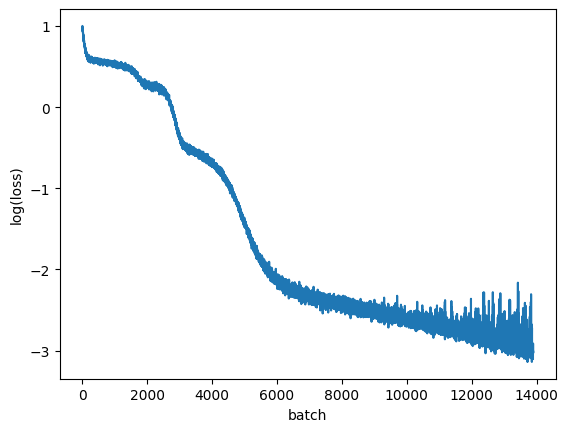

In [ ]:
plt.plot(np.log10(train_history[100:]))
plt.ylabel("log(loss)")
plt.xlabel("batch")

Me imagino que el ancho del grafico indica que hay overfitting: la loss depende cada vez mas de los batches individuales. No parece estar empeorando en los peores casos: el "lim sup" sigue en 10^-2, pero igual no voy a seguir entrenando.

Aunque no haya un dataset fijo, puede que la simetrizacion haga que algunos inputs a la red neuronal sean mas probables, y la red esta haciendo overfitting a esos.

https://mathworld.wolfram.com/UniformDifferenceDistribution.html

Como la distribucion de x1 y x2 es uniforme, la distribucion de x1-x2, que es una variable que le paso a la red para asegurar simetria de traslacion, tiende a tomar valores cerca de 0.

Me imagino que podria corregir un poco esto multiplicando la loss por un termino inversamente proporcional a que tan probable es el conjunto de estados en la que esta evaluada, asi le da menos importancia a ajustar correctamente los estados muy comunes.

Como en una trayectoria real los estados en los que las particulas estan alejadas son mas frecuentes (porque ahi la energia cinetica es mas baja), es importante que el modelo funcione bien en esos

In [ ]:
torch.save(model.state_dict(), "half_sym_m3.pt")

In [ ]:
n_epochs = 10
torch.random.manual_seed(5)

model2 = SymmetricLagrangianNet()
model2 = model2.to(DEVICE)

prediction2 = lambda state: getAcceleration(model2, state[0:4], state[4:8])

criterion = nn.MSELoss()
optimizer2 = optim.Adam(model2.parameters(), lr=0.001)
#

train_history2 = []

In [ ]:
starting_epoch = 0 #Por si quiero resumir el entrenamiento

# Como el batch_size es grande, la probabilidad real de cada batch
# entero es minuscula. Quise usar un multiplo de la probabilidad,
# pero los resultados son o muy chicos o muy grandes.
# Voy a usar la mediana de las probabilidades
probability = lambda state: 2.6*(1 - torch.abs(state[0] - state[2]))*(1 - torch.abs(state[1] - state[3]))
batch_probability = lambda batch: torch.median(vmap(probability, in_dims=0)(batch))

for epoch in trange(starting_epoch, n_epochs):
  train_states, train_targets = getEpochData()

  for i in range(n_batches_per_epoch):
    batch_states = train_states[i]
    batch_targets = train_targets[i]

    output = vmap(prediction2, in_dims=0)(batch_states)
    #print(output)
    #print(probability(batch_states[0]))
    #print(batch_probability(batch_states))
    loss = criterion(output, batch_targets) / batch_probability(batch_states)

    optimizer2.zero_grad()
    loss.backward()
    optimizer2.step()

    real_loss = loss * (batch_probability(batch_states))

    print(str(np.round(real_loss.detach().item(),5)))

    train_history2.extend([real_loss.detach().item()])

  0%|          | 0/10 [00:00<?, ?it/s]

2368.06519
292.31232
53.71427
39.22239
33.75444
30.39871
29.20099
28.45154
28.23272
27.09626
26.80218
26.3927
26.22908
25.64063
25.39031
24.21708
23.90182
23.10756
23.7638
23.22171
23.64833
21.92381
22.72216
22.47394
21.89511
21.53947
21.24724
21.22728
19.89733
19.79812
19.72871
19.47249
19.16248
19.78014
20.06221
18.3396
18.73122
19.0165
17.88871
18.75968
17.77192
18.15469
18.09948
17.63792
17.37864
16.77158
15.89294
16.68329
17.04179
16.92454
15.87019
15.86592
15.74737
15.59495
15.70002
14.40884
15.2611
15.06008
15.01882
15.42166
14.81634
14.34233
14.40295
14.60076
14.43228
13.96025
13.83401
14.14217
13.78674
13.59528
13.52335
13.70944
13.64358
13.11476
12.47306
13.42601
12.99983
12.49016
12.55815
12.33808
12.54522
12.43038
11.17206
11.93181
12.24537
11.74157
11.73962
11.55447
10.86001
11.00782
10.88398
10.75943
11.49891
9.99285
10.62187
10.75124
9.82377
10.3493
10.94628
10.03384
10.1251
10.23924
9.79668
9.81923
10.29466
9.15983
9.78393
9.90531
9.54666
9.78832
9.21141
9.34296
8.65726

 10%|█         | 1/10 [00:55<08:22, 55.86s/it]

1.90798
1.91179
2.01659
2.1964
2.08843
1.75151
2.11894
1.71418
2.0148
2.00003
2.06721
1.88626
1.82253
1.96646
1.90626
1.81765
1.86577
1.96194
1.81562
1.90817
1.77432
1.97908
2.07905
2.07109
1.86804
1.91782
1.71293
1.86279
1.81304
1.92367
1.96082
2.22576
1.83202
2.02978
1.92847
1.86603
1.83189
1.96512
2.02455
1.99629
1.74674
1.90793
2.01421
1.95375
1.83207
1.89224
1.96923
1.90368
1.89553
1.9439
1.94348
1.82503
1.8959
1.84602
2.04942
1.87283
1.9228
1.84504
1.85562
1.89706
1.98154
1.78048
1.88857
1.67219
1.85154
2.14381
1.97987
1.89437
1.91823
1.94607
1.91499
1.91801
2.03747
1.73993
1.94528
1.85194
1.85934
1.79627
1.79922
1.97837
1.8701
1.97534
1.8554
1.75986
1.86164
1.84817
1.89762
1.85485
1.94232
2.00869
1.99151
1.75641
1.95685
2.02618
1.8095
1.86256
1.75513
1.8095
1.91199
1.90525
1.88689
1.88489
1.92648
1.98447
1.87449
1.79734
1.96745
1.90724
2.03638
2.01138
1.81818
1.83229
1.80048
2.08603
1.79489
1.96473
1.85185
2.00903
1.87316
1.85578
1.82093
1.80633
1.91597
1.78823
1.83657
2.03098
1

 20%|██        | 2/10 [01:50<07:22, 55.33s/it]

0.24437
0.22169
0.22353
0.21696
0.21008
0.20747
0.20168
0.23027
0.21485
0.21392
0.23375
0.21832
0.21617
0.20671
0.24297
0.20728
0.22182
0.19758
0.20912
0.21006
0.20127
0.22897
0.23181
0.22868
0.22258
0.19542
0.21565
0.23079
0.20902
0.23238
0.19379
0.22114
0.20554
0.23695
0.21397
0.22932
0.21771
0.21567
0.21124
0.22715
0.22468
0.22419
0.21299
0.23989
0.21846
0.23882
0.22063
0.21278
0.2157
0.21098
0.20895
0.21864
0.21692
0.21486
0.1962
0.24006
0.21282
0.2076
0.22214
0.22087
0.21111
0.19115
0.22166
0.21076
0.20494
0.20261
0.19626
0.20121
0.21088
0.21704
0.22363
0.20459
0.2306
0.22272
0.21751
0.21807
0.20829
0.21751
0.21924
0.22102
0.21349
0.20771
0.20539
0.21757
0.20211
0.21205
0.19899
0.20852
0.21178
0.20151
0.20416
0.20772
0.21404
0.19751
0.20949
0.19418
0.19991
0.20637
0.18554
0.18621
0.19606
0.21545
0.22
0.20699
0.21617
0.20786
0.20892
0.21261
0.23514
0.20906
0.18492
0.21882
0.19786
0.19833
0.21945
0.20914
0.19831
0.20172
0.21004
0.19882
0.20902
0.2215
0.19531
0.20022
0.22139
0.19617


... (12 outputs left out)

 90%|█████████ | 9/10 [08:48<01:00, 60.13s/it]

0.00082
0.00057
0.00092
0.00118
0.00143
0.00116
0.00082
0.00061
0.00055
0.00081
0.00142
0.00192
0.00196
0.00147
0.00086
0.00061
0.00055
0.0008
0.00095
0.0009
0.00066
0.00053
0.0006
0.00074
0.00062
0.00058
0.00065
0.00079
0.00108
0.00126
0.00101
0.00077
0.00068
0.00066
0.00088
0.00082
0.00062
0.00062
0.00055
0.00054
0.00047
0.00066
0.00075
0.00087
0.00117
0.00146
0.00179
0.002
0.00133
0.00094
0.00081
0.00063
0.00056
0.00059
0.00078
0.00069
0.0008
0.00097
0.00096
0.00068
0.00058
0.00102
0.00192
0.0024
0.00358
0.00456
0.00498
0.00345
0.00208
0.00153
0.00119
0.00096
0.00104
0.00118
0.00196
0.00283
0.00318
0.00233
0.00163
0.00112
0.0009
0.00086
0.00123
0.00159
0.00155
0.00168
0.00191
0.00136
0.00096
0.00068
0.0006
0.00058
0.00066
0.00099
0.00136
0.00109
0.00074
0.00061
0.00061
0.00081
0.00078
0.00062
0.0006
0.00058
0.00058
0.0006
0.00052
0.00059
0.00056
0.00074
0.00102
0.0015
0.00236
0.00243
0.00214
0.00192
0.00163
0.00152
0.00098
0.0007
0.00074
0.00105
0.00138
0.00205
0.00314
0.00628
0.008

100%|██████████| 10/10 [09:54<00:00, 59.42s/it]

0.00112
0.00123
0.00093
0.00055


Text(0.5, 0, 'batch')

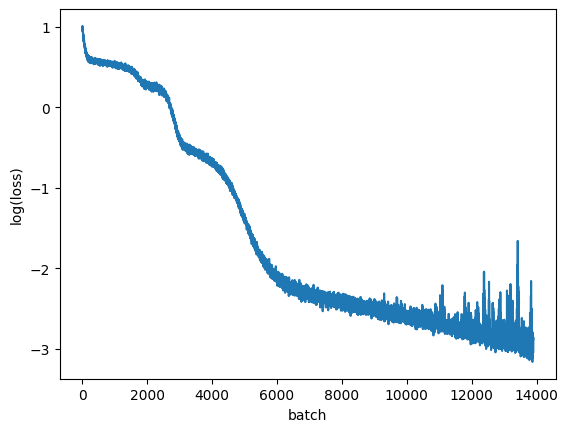

In [ ]:
plt.plot(np.log10(train_history2[100:-6000]))
plt.ylabel("log(loss)")
plt.xlabel("batch")

In [ ]:
torch.save(model2.state_dict(), "half_sym_weighted_m3.pt")

No parece haber ayudado mucho. El grafico es un poco mas angosto, pero ahora tiene picos mucho mas altos. Puede que esos picos sean debido a batches muy poco probables que hacen que el modelo ajuste demasiado.

Antes de hacer comparaciones, entreno una red que no sea lagrangiana para comparar.

In [ ]:
class SymmetricBaselineNet(nn.Module):
  def __init__(self):
    super().__init__()
    self.fc1 = nn.Linear(8,600)
    self.fc2 = nn.Linear(600,600)
    self.fc3 = nn.Linear(600,4)
    self.act = nn.Softplus()

    self.fc1.weight.data = nn.init.normal_(self.fc1.weight.data, 0, 2.2/np.sqrt(600))
    self.fc2.weight.data = nn.init.normal_(self.fc2.weight.data, 0, 0.58/np.sqrt(600))
    self.fc3.weight.data = nn.init.normal_(self.fc3.weight.data, 0, 600/np.sqrt(600))

  def forward(self, pos, vel):
    r1,r2 = pos.split(2)
    v1,v2 = vel.split(2)

    # Simetria de traslacion/cons. momento
    # Pongo el origen en r2
    r1 = r1 - r2
    r2 = r2 - r2

    # Simetria galileana
    # Como no voy a usar Euler-Lagrange, no importa que esta sea
    # una cuasi-simetria del lagrangiano, porque es una simetria
    # exacta de la ecuacion de newton
    v1 = v1 - v2
    v2 = v2 - v2

    x = torch.cat((r1,r2,v1,v2))
    #x = torch.cat((pos,vel))
    x = self.act(self.fc1(x))
    x = self.act(self.fc2(x))
    x = self.fc3(x)
    return x

In [ ]:
n_epochs = 5
torch.random.manual_seed(5)

model3 = SymmetricBaselineNet()
model3 = model3.to(DEVICE)

#predicter3 = lambda state: model3(*state.split(4))
prediction3 = lambda state: model3(state[0:4], state[4:8])

criterion = nn.MSELoss()
optimizer3 = optim.Adam(model3.parameters(), lr=0.001)

train_history3 = []

In [ ]:
starting_epoch = 0

for epoch in trange(starting_epoch, n_epochs):
  train_states, train_targets = getEpochData()

  for i in range(n_batches_per_epoch):
    batch_states = train_states[i]
    batch_targets = train_targets[i]

    output = vmap(prediction3, in_dims=0)(batch_states)
    #print(output[0:5])
    loss = criterion(output, batch_targets)

    optimizer3.zero_grad()
    loss.backward()
    optimizer3.step()

    print(str(np.round(loss.detach().item(),5)))

    train_history3.extend([loss.detach().item()])

  0%|          | 0/5 [00:00<?, ?it/s]

111755.875
819138.0
127412.40625
97717.47656
380296.0625
257873.46875
42487.85938
17062.09766
130546.51562
186534.17188
125023.72656
33265.34375
873.48517
37441.51172
84320.73438
88104.67188
50156.98047
10728.85254
1000.90045
19431.98438
41467.34375
45065.00391
29032.31641
8836.38086
124.10139
6218.52637
18055.7168
23426.98633
18094.38477
7583.74658
674.86261
1403.59229
7075.69531
11493.39062
10895.44434
5984.10059
1271.19861
146.41077
2507.21216
5444.98193
6097.44678
4050.25073
1249.57056
22.96838
889.25244
2581.43115
3269.27148
2429.40649
926.14948
45.93189
336.76526
1234.59631
1741.46936
1399.62549
562.92316
36.95251
164.567
677.57294
953.59863
756.89221
291.73822
15.00705
118.33658
403.79425
532.03577
380.04971
121.62274
4.23771
102.01559
258.05585
288.80493
170.55751
33.47909
9.24814
90.2308
163.38748
145.13931
61.92233
4.28461
20.67598
76.63995
96.34915
61.03178
14.12607
3.43188
29.23617
55.51625
45.2152
17.77801
1.18499
10.81343
27.33568
30.95037
16.65513
1.93945
3.67712
13.9848

 20%|██        | 1/5 [00:04<00:16,  4.20s/it]

0.36522
0.1995
0.03245
0.13396
0.19776
0.12672
0.11624
0.11071
0.04533
0.07538
0.13798
0.09971
0.02829
0.04739
0.07865
0.05354
0.04973
0.06239
0.03887
0.02431
0.05792
0.06524
0.03378
0.03544
0.04707
0.04357
0.04045
0.05957
0.05063
0.02212
0.03512
0.05424
0.04619
0.02904
0.0264
0.0332
0.02813
0.0436
0.04819
0.03347
0.0264
0.0259
0.03293
0.02987
0.02711
0.03035
0.02211
0.02517
0.02515
0.02522
0.02994
0.02075
0.02244
0.02069
0.02092
0.02363
0.02252
0.02143
0.02092
0.02134
0.01988
0.01885
0.01786
0.01907
0.02378
0.02356
0.02323
0.02041
0.02256
0.02395
0.02054
0.0231
0.02334
0.02445
0.02186
0.01919
0.02012
0.02442
0.0215
0.02078
0.02227
0.02364
0.0226
0.02772
0.02628
0.02503
0.02247
0.02776
0.02727
0.02246
0.01803
0.02288
0.02494
0.0219
0.0198
0.02228
0.02669
0.02292
0.01924
0.01874
0.02025
0.02193
0.02626
0.02641
0.02318
0.01723
0.01852
0.02128
0.02375
0.02373
0.02099
0.02435
0.02266
0.02013
0.02124
0.01986
0.02113
0.02342
0.02379
0.02778
0.02918
0.02411
0.0232
0.02496
0.02133
0.02098
0.02

 40%|████      | 2/5 [00:08<00:12,  4.19s/it]

13.49575
19.53055
28.59784
41.96794
61.9221
91.36584
135.07982
198.76083
292.34256
423.73059
605.98364
833.90112
1099.76123
1326.51929
1430.7583
1260.61011
830.80792
312.83408
32.83001
114.81422
337.46365
373.82422
182.17657
34.39141
89.62637
181.14442
134.53348
40.79488
45.92331
96.98716
80.51972
31.11388
32.98871
54.11019
38.13438
19.60359
30.24571
33.16705
17.12792
16.22555
24.4857
14.95955
7.67774
16.74388
16.33881
5.66603
8.19386
14.12937
7.20585
3.09436
9.35055
8.36483
1.89798
3.95313
7.0687
2.85309
1.10502
4.90206
4.15731
0.52003
2.0905
3.96194
1.35097
0.37298
2.61985
2.22454
0.17811
0.95616
2.01247
0.71569
0.14186
1.20432
1.0449
0.09594
0.48167
0.9902
0.38291
0.09244
0.56891
0.51818
0.09124
0.23026
0.43591
0.1896
0.08338
0.26826
0.22802
0.05592
0.1287
0.20399
0.07981
0.03902
0.13706
0.11653
0.02809
0.06569
0.11223
0.04732
0.0199
0.07184
0.06152
0.01389
0.02814
0.04857
0.02273
0.00955
0.03174
0.03671
0.0112
0.00914
0.02758
0.02374
0.0075
0.00977
0.02101
0.01771
0.00873
0.00987
0

... (2 outputs left out)

 80%|████████  | 4/5 [00:17<00:04,  4.32s/it]

0.09239
0.02355
0.02399
0.06899
0.03826
0.00735
0.04012
0.04398
0.00866
0.01607
0.03619
0.01617
0.00382
0.02124
0.01902
0.00231
0.00879
0.01749
0.00656
0.00178
0.01044
0.00872
0.00109
0.00383
0.00704
0.00248
0.00086
0.00418
0.00346
0.0006
0.00166
0.00292
0.00113
0.00056
0.0023
0.00198
0.00053
0.00076
0.00163
0.00111
0.00035
0.0006
0.00079
0.00044
0.00043
0.00058
0.00047
0.00034
0.0005
0.00049
0.00038
0.00037
0.00047
0.00038
0.0004
0.00045
0.00032
0.0004
0.00054
0.00043
0.00033
0.00044
0.00049
0.00034
0.00032
0.00047
0.00041
0.0003
0.00035
0.00043
0.00043
0.00029
0.00029
0.00029
0.00032
0.00032
0.00029
0.00038
0.00034
0.00029
0.00035
0.00043
0.0004
0.00032
0.0003
0.0003
0.00031
0.00033
0.0003
0.00035
0.00039
0.00036
0.00035
0.00042
0.0004
0.00032
0.00034
0.00029
0.00034
0.00036
0.00028
0.00031
0.00034
0.00032
0.00035
0.00036
0.00036
0.00027
0.00029
0.00035
0.00028
0.00035
0.00036
0.0003
0.00033
0.00039
0.00035
0.00028
0.00027
0.00034
0.00038
0.0003
0.0003
0.00035
0.00029
0.00032
0.00035

100%|██████████| 5/5 [00:21<00:00,  4.30s/it]

0.00014
0.00018
0.0002
0.00018
0.00017
0.00013
0.00013
0.00014
0.00019
0.00024
0.00022
0.00018
0.00014


In [ ]:
model = SymmetricLagrangianNet()
model2 = SymmetricLagrangianNet()

model.load_state_dict(torch.load("half_sym_m3.pt"))
model2.load_state_dict(torch.load("half_sym_weighted_m3.pt"))

Simulo una trayectoria con las tres redes y la aceleracion analitica

In [ ]:
# Robado de https://colab.research.google.com/drive/1CSy-xfrnTX28p1difoTA8ulYw0zytJkq
def rk4_step(f, h, t, x):
  # one step of runge-kutta integration
  k1 = h * f(x, t)
  k2 = h * f(x + k1/2, t + h/2)
  k3 = h * f(x + k2/2, t + h/2)
  k4 = h * f(x + k3, t + h)
  return x + 1/6 * (k1 + 2 * k2 + 2 * k3 + k4)

In [ ]:
initial_state = torch.tensor(
    [0,0,0,1,0.5,0,0.5,0], device = DEVICE
)

real_trajectory = initial_state.unsqueeze(0)
model_trajectory = initial_state.unsqueeze(0)
model_median_prob_trajectory = initial_state.unsqueeze(0)
model_baseline_trajectory = initial_state.unsqueeze(0)

realChange = lambda state, t: torch.cat((state[4:8], realAcceleration(state[0:4], state[4:8])))
modelChange = lambda L, state, t: torch.cat((state[4:8], getAcceleration(L,state[0:4], state[4:8])))
modelBaselineChange = lambda state, t: torch.cat((state[4:8], prediction3(state)))

t = torch.linspace(0,10,1000)
dt = 10/1000

for i in tqdm.tqdm(t):
  real_trajectory = torch.cat((real_trajectory, (rk4_step(realChange, dt, 0, real_trajectory[-1])).unsqueeze(0)))
  model_trajectory = torch.cat((model_trajectory, (rk4_step(partial(modelChange, model), dt, 0, model_trajectory[-1])).unsqueeze(0)))
  model_median_prob_trajectory = torch.cat((model_median_prob_trajectory, (rk4_step(partial(modelChange, model2), dt, 0, model_median_prob_trajectory[-1])).unsqueeze(0)))
  model_baseline_trajectory = torch.cat((model_baseline_trajectory, (rk4_step(modelBaselineChange, dt, 0, model_baseline_trajectory[-1]).unsqueeze(0))))

100%|██████████| 1000/1000 [01:58<00:00,  8.40it/s]


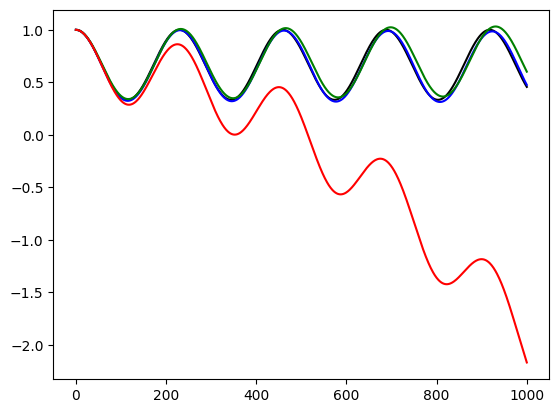

In [ ]:
plt.plot(real_trajectory[:,3].cpu(), color="black")
plt.plot(model_median_prob_trajectory[:,3].cpu().detach(), color="blue")
plt.plot(model_trajectory[:,3].cpu().detach(), color="green")
plt.plot(model_baseline_trajectory[:,3].cpu().detach(), color="red")

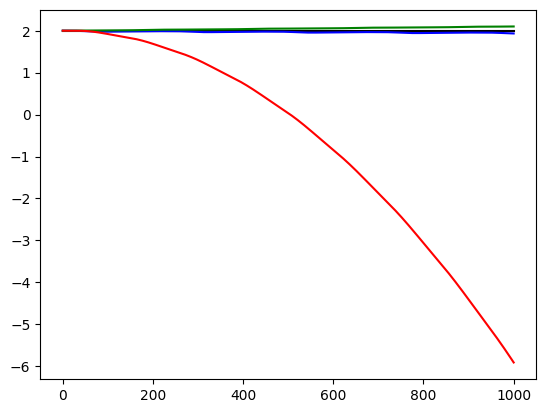

In [ ]:
# Centro de masa

plt.plot(m1 * real_trajectory[:,1].cpu() + m2 * real_trajectory[:,3].cpu(), color="black")
plt.plot(m1 * model_median_prob_trajectory[:,1].cpu().detach() + m2 * model_median_prob_trajectory[:,3].cpu().detach(), color="blue")
plt.plot(m1 * model_trajectory[:,1].cpu().detach() + m2 * model_trajectory[:,3].cpu().detach(), color="green")
plt.plot(m1 * model_baseline_trajectory[:,1].cpu().detach() + m2 * model_baseline_trajectory[:,3].cpu().detach(), color="red")

Las lagrangianas son mucho mejores. Voy a comparalas entre si

In [ ]:
model.eval()
model2.eval()

def get_distance(real_state, model_state):
  real_pos, real_vel = real_state.split(4)
  model_pos, model_vel = model_state.split(4)

  # No es realmente la distancia entre dos puntos,
  # pero sirve igual para ver que tan parecidos
  # son los estados
  return ((real_pos - model_pos)**2).sum().cpu().detach()

initials = []
model_errors = []
model_weighted_errors = []

for _ in trange(10):
  initial_state = torch.rand(size=(8,), device=DEVICE)
  initials.extend([initial_state])
  real_trajectory = initial_state.unsqueeze(0)
  model_trajectory = initial_state.unsqueeze(0)
  model_median_prob_trajectory = initial_state.unsqueeze(0)

  model_error = []
  model_median_prob_error = []

  t = torch.linspace(0,2,200)
  dt = 10/1000

  for i in t:
    real_trajectory = torch.cat((real_trajectory, (rk4_step(realChange, dt, 0, real_trajectory[-1])).unsqueeze(0)))
    model_trajectory = torch.cat((model_trajectory, (rk4_step(partial(modelChange, model), dt, 0, model_trajectory[-1]).unsqueeze(0))))
    model_median_prob_trajectory = torch.cat((model_median_prob_trajectory, (rk4_step(partial(modelChange, model2), dt, 0, model_median_prob_trajectory[-1]).unsqueeze(0))))

    model_error.extend([get_distance(real_trajectory[-1], model_trajectory[-1])])
    model_median_prob_error.extend([get_distance(real_trajectory[-1], model_median_prob_trajectory[-1])])

  model_errors.extend([model_error])
  model_weighted_errors.extend([model_median_prob_error])

100%|██████████| 10/10 [03:49<00:00, 22.93s/it]


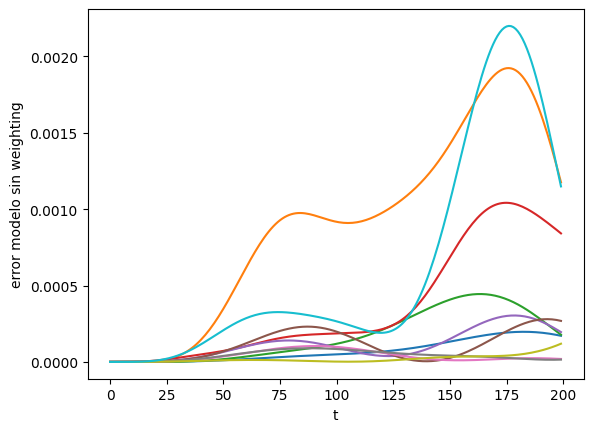

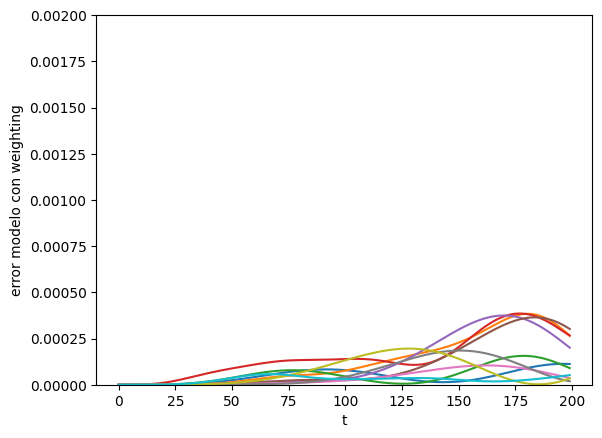

In [ ]:
plt.ylabel("error modelo sin weighting")
plt.xlabel("t")
for i in model_errors:
  plt.plot(i)
plt.show()

plt.ylabel("error modelo con weighting")
plt.ylim([0,0.002])
plt.xlabel("t")
for i in model_weighted_errors:
  plt.plot(i)
plt.show()

O sea que corregir el overfitting mejora las predicciones

# Mejora de conservacion de energia usando simetria temporal

Si para un sistema tengo una trayectoria $\vec{r}(t)$, hay dos formas de llegar a la trayectoria "en reversa" $\vec{s}(t) = \vec{r}(-t)$

La primera es matematica. Si tengo la velocidad y la aceleracion, entonces

$$\vec{s}(t+dt) = \vec{s}(t) + \dot{\vec{s}}(t)dt = \vec{r}(-t) - \dot{\vec{r}}(-t)dt$$
$$\dot{\vec{s}}(t+dt) = \dot{\vec{s}}(t) +\ddot{\vec{s}}(t)dt = -\dot{\vec{r}}(-t) + \ddot{\vec{r}}(-t)dt$$

La segunda es fisica. Si las ecuaciones de movimiento son reversibles, para toda trayectoria con condiciones iniciales $\vec{r}_0, \dot{\vec{r}}_0$ hay otra trayectoria, con condiciones iniciales $\vec{r}_0, -\dot{\vec{r}}_0$ que es identica pero en reversa.

Si la red baseline hace que **todas** las trayectorias pierdan energia, entonces ya no son equivalentes las dos versiones en reversa de una trayectoria: la matematica gana energia, y la fisica pierde energia (porque es una trayectoria mas). Se me ocurre que podria alternar entre ambas para intentar que se conserve mejor la energia.

Lo que voy a hacer es usar la baseline que ya entrene, y alternar entre usarla normalmente y usar la reversa matematica de la trayectoria con condiciones iniciales opuestas. No voy a entrenarla, solo usarla.

pero primero tengo que ver que **todas** las trayectorias pierdan energia

100%|██████████| 10/10 [01:15<00:00,  7.51s/it]


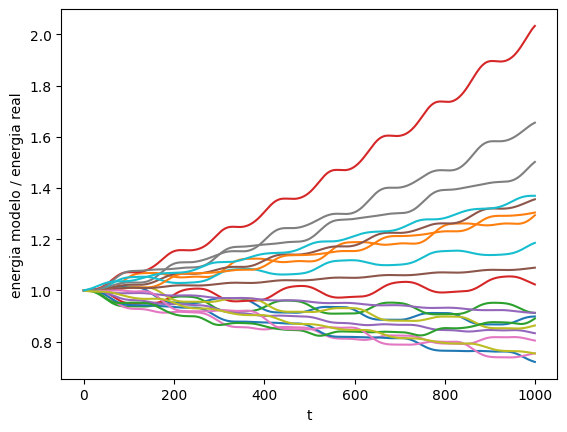

In [ ]:
energies = []
initials = []

def get_energy(state):
  pos, vel = state.split(4)
  return m1/2 * (vel[0]**2 + vel[1]**2) + m2/2 * (vel[2]**2 + vel[3]**2) + k/2 * ((pos[2] - pos[0])**2 + (pos[3] - pos[1])**2)

for _ in trange(10):
  energy = []

  initial_state = torch.rand(size=(8,), device=DEVICE)
  initials.extend([initial_state])
  real_trajectory = initial_state.unsqueeze(0)
  model_baseline_flipping_trajectory = initial_state.unsqueeze(0)

  t = torch.linspace(0,10,1000)
  dt = 10/1000

  for i in t:
    real_trajectory = torch.cat((real_trajectory, (rk4_step(realChange, dt, 0, real_trajectory[-1])).unsqueeze(0)))
    model_baseline_flipping_trajectory = torch.cat((model_baseline_flipping_trajectory, (rk4_step(modelBaselineChange, dt, 0, model_baseline_flipping_trajectory[-1]).unsqueeze(0))))

    real_energy = get_energy(real_trajectory[-1])
    model_energy = get_energy(model_baseline_flipping_trajectory[-1])
    energy.extend([(model_energy / real_energy).cpu().item()])

  plt.plot(energy)
  energies.extend([energy])

  energy = []
  initial_pos, initial_vel = initial_state.split(4)
  initial_state = torch.cat((initial_pos, -initial_vel))
  initials.extend([initial_state])
  real_trajectory = initial_state.unsqueeze(0)
  model_baseline_flipping_trajectory = initial_state.unsqueeze(0)

  for i in t:
    real_trajectory = torch.cat((real_trajectory, (rk4_step(realChange, dt, 0, real_trajectory[-1])).unsqueeze(0)))
    model_baseline_flipping_trajectory = torch.cat((model_baseline_flipping_trajectory, (rk4_step(modelBaselineChange, dt, 0, model_baseline_flipping_trajectory[-1]).unsqueeze(0))))

    real_energy = get_energy(real_trajectory[-1])
    model_energy = get_energy(model_baseline_flipping_trajectory[-1])
    energy.extend([(model_energy / real_energy).cpu().item()])


  plt.plot(energy)
  energies.extend([energy])
plt.ylabel("energia modelo / energia real")
plt.xlabel("t")
plt.show()


Asi que al final no todas pierden energia. Al menos en este caso de las dos particulas con interaccion elastica

In [ ]:
# Cual es esa que crece rapido?
for i in energies:
  print(i[-1])

0.8980379104614258
1.2934541702270508
0.911609411239624
1.0232009887695312
0.8327213525772095
1.3557628393173218
0.8040304183959961
1.6549584865570068
0.8629630208015442
1.1856119632720947
0.7205958962440491
1.3041296005249023
0.8900431990623474
2.0328726768493652
0.9126099348068237
1.0887030363082886
0.7539471983909607
1.501656174659729
0.7536704540252686
1.3693866729736328


In [ ]:
initial_state = torch.tensor(data=[ 0.0491,  0.3736,  0.6786,  0.1596, -0.2163, -0.9965, -0.5093, -0.8976], device=DEVICE)

t = torch.linspace(0,500,50000)
dt = 10/10000

real_trajectory = initial_state.unsqueeze(0)
model_baseline_trajectory = initial_state.unsqueeze(0)
real_energy = [get_energy(initial_state)]
model_energy = [get_energy(initial_state)]

for i in tqdm.tqdm(t):
  real_trajectory = torch.cat((real_trajectory, (rk4_step(realChange, dt, 0, real_trajectory[-1])).unsqueeze(0)))
  model_baseline_trajectory = torch.cat((model_baseline_trajectory, (rk4_step(modelBaselineChange, dt, 0, model_baseline_trajectory[-1]).unsqueeze(0))))

  real_energy.extend([get_energy(real_trajectory[-1]).cpu().item()])
  model_energy.extend([get_energy(model_baseline_trajectory[-1]).cpu().item()])

100%|██████████| 50000/50000 [02:59<00:00, 277.82it/s]


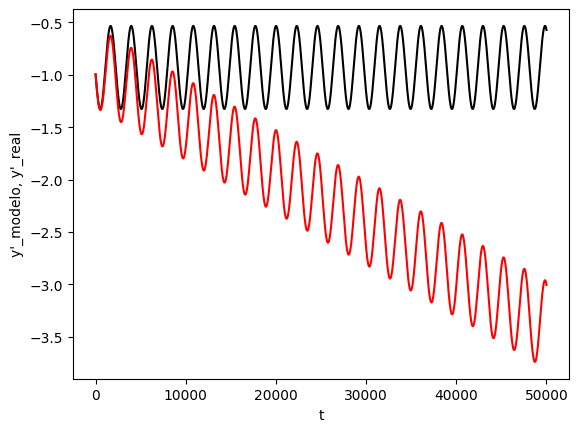

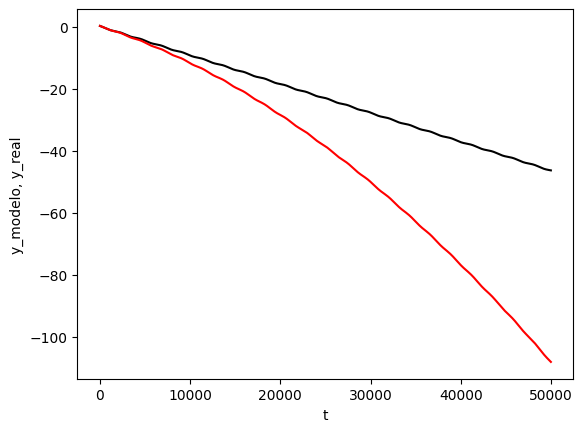

In [ ]:
plt.ylabel("y'_modelo, y'_real")
plt.xlabel("t")
plt.plot(real_trajectory[:,5].cpu(), color="black")
plt.plot(model_baseline_trajectory[:,5].cpu().detach(), color="red")
plt.show()

plt.ylabel("y_modelo, y_real")
plt.xlabel("t")
plt.plot(real_trajectory[:,1].cpu(), color="black")
plt.plot(model_baseline_trajectory[:,1].cpu().detach(), color="red")
plt.show()

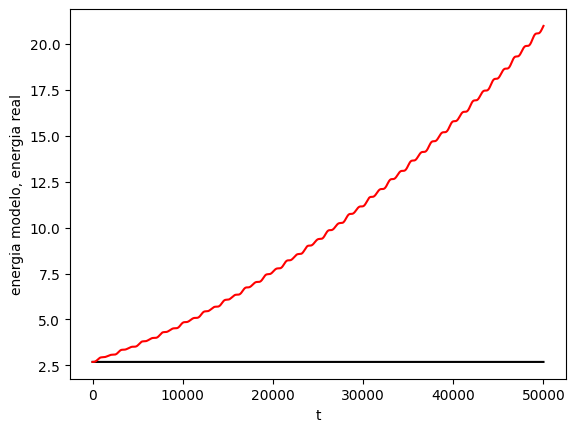

In [ ]:
#real_energy[0] = real_energy[0].cpu()
#model_energy[0] = model_energy[0].cpu()

plt.ylabel("energia modelo, energia real")
plt.xlabel("t")
plt.plot(real_energy, color="black")
plt.plot(model_energy, color="red")